# 15 — Predicciones tempranas: los primeros resultados reales

## El objetivo

> Predecir **cuántas solicitudes de triage llegarán al SES Hospital Universitario de Caldas**, como
> una **distribución** (un valor central y un rango). De ahí sale la **probabilidad de que el triage
> suba** por encima de lo que anuncia su calendario. Cada predicción lleva sus **razones**: qué del
> contexto interno y externo la mueve.

Es un solo proyecto. Los cuadernos 01-14 sirvieron para saber **con qué entrenar** y **cómo comprobar
la fiabilidad**. Este cuaderno junta las primeras predicciones reales, buenas o malas, para ver **cómo se
comporta hoy y qué falta**. No se espera que funcione a la primera. Si lo hiciera, habría que
sospechar.

## Lo que se decidió (docs/CONTEXTO.md, 2026-09-30 y 2026-10-01)

| | Decisión |
|---|---|
| **Qué se predice** | El conteo diario de triage a 1-7 días, el año completo y la hora de saturación |
| **Qué entrega** | Una **distribución** (9 cuantiles). La regresión es complemento, no método principal |
| **Qué es «subir»** | Pasar lo que anuncia el calendario. **Pico** = pasarlo en más de una desviación (≈ +11 %) |
| **Con qué se entrena** | **Todos los años con registro (2020-2026)**, con la COVID marcada, y **todo el contexto**: salud, clima, social, red de salud, catástrofes, eventos, ENSO. **Solo lo que se sabe el día de la predicción** |
| **Contra qué se prueba** | **2026**, con datos que el modelo nunca vio |
| **Qué modelos** | Todos en competencia: series de tiempo (SARIMAX, Prophet), modelo fundacional de series (Chronos-2), árboles (LightGBM), regresión binomial negativa, bases y MedGemma |
| **Confiabilidad esperada** | **60-70 %**. Por encima de eso hay que revisar el sobreentrenamiento o una fuga de información |

## Las tres pruebas

| Prueba | Pregunta | Cómo |
|---|---|---|
| **1. Corto plazo** | ¿Qué pasará los próximos 7 días? | Cada día de 2026, el modelo predice los 7 siguientes con lo que sabía hasta ayer |
| **2. El año a ciegas** | Desde diciembre de 2025: ¿cómo será cada mes de 2026? | Una sola predicción hecha el 31-12-2025 hasta septiembre |
| **3. La hora** | ¿A qué hora se satura el día predicho? | La predicción del día repartida con el perfil horario |

## Los tres experimentos, para saber qué aporta cada cosa

| | Años de entrenamiento | Contexto externo |
|---|---|---|
| **E0** | 2022-2024 (fase A) | no |
| **E1** | 2020-2025, con la COVID marcada | no |
| **E2** | 2020-2025, con la COVID marcada | **todo** |

E1 contra E0 dice qué aportan **más años**. E2 contra E1 dice qué aporta **el contexto**.

El motor está en `notebooks/pronostico.py` y las corridas largas escriben en `salidas/pronostico/`.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import statsmodels.api as sm
from matplotlib import pyplot as plt
import pronostico as pr

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
COLOR = {"ingenuo": MUDO, "control": TINTA2, "glm_binneg": AZUL, "lightgbm": VERDE, "sarimax": VIOLETA,
         "prophet": AMARILLO, "chronos2": MAGENTA, "chronos2_cal": ROJO, "llm": NARANJA,
         "anio_pasado": MUDO, "regresion_anual": AZUL}
NOMBRE = {"ingenuo": "Ingenuo (semana pasada)", "control": "Control (calendario + nivel)", "glm_binneg": "Regresión binomial negativa",
          "lightgbm": "LightGBM (árboles)", "sarimax": "SARIMAX (serie de tiempo)", "prophet": "Prophet (serie de tiempo)",
          "chronos2": "Chronos-2 solo", "chronos2_cal": "Chronos-2 (IA de series)", "anio_pasado": "Igual que el año pasado",
          "regresion_anual": "Regresión anual (calendario + nivel)", "lightgbm_afinado": "LightGBM afinado",
          "xgboost_afinado": "XGBoost afinado", "gbr_afinado": "GradientBoosting afinado",
          "comb_sarimax_lightgbm": "SARIMAX + LightGBM (combinación)", "comb_4_modelos": "Combinación de 4 modelos"}
CRIT = ["BSS sube %", "BSS pico %", "R2 desvio %", "acierta sube/baja %", "AUC pico", "cob80 %", "error <=10 %", "MAPE %", "n"]
SEM = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
color = lambda m: COLOR.get(m.split("_cada")[0], COLOR["llm"] if m.startswith("llm") else MUDO)

def leer(exp, desde="2025-12-31", modelos=None):
    P, U = pr.leer(exp=exp)
    P = P[(P.origen >= desde) & ~P.modelo.str.startswith("llm") & ~P.modelo.str.contains("_cada")]
    if not modelos: P = P[~P.modelo.str.startswith("comb_") & ~P.modelo.str.endswith("_afinado")]
    if modelos: P = P[P.modelo.isin(modelos)]
    return P, U

pr.usar("e2"); y, cal = pr.cargar()
print(f"triage diario: {y.notna().sum()} días con dato, {y.index[0].date()} a {y.index[-1].date()}")

triage diario: 2452 días con dato, 2020-01-01 a 2026-09-20


---
# 1. Los datos: qué se sabe y cuándo

La regla que manda sobre todas: **una predicción hecha el día *o* solo puede usar lo que se sabía el
día *o***. Lo que se sabe por adelantado (calendario, eventos programados) entra con el día que se
predice. Lo demás, con su último valor conocido.

,dato,fuente,¿cuándo se sabe?,capa
0,Triage diario,salidas/triage_diario.parquet,hasta el día de la predicción,nivel y memoria
1,Calendario de Colombia,calendario_Colombia.csv,por adelantado,calendario
2,COVID (dos fases),fechas fijas,por adelantado,calendario
3,"Feria, eventos de Manizales, fiestas de Caldas...","eventos_*, fiestas_*, calendario",por adelantado (programados),eventos
4,"IRA de Manizales (total, 0-4, 60+), consultas ...",Power BI 995 + microdatos,semana epidemiológica anterior,salud
5,"Agresión animal, intento de suicidio, varicela...",Power BI + microdatos,semana anterior,salud
6,"Temperatura, humedad, lluvia, radiación, vient...",clima_unificado.csv.gz,hasta el día anterior,clima
7,"Lesiones de tránsito, lesiones personales, hom...",seguridad_mindefensa.csv.gz,hasta el día anterior,social
8,Nueva EPS: cambio de 28 días y peso en el triage,triage_entidad.parquet,hasta el día de la predicción,red
9,Desastre activo (incluye el terremoto del 10-0...,desastres_manizales_2020_2026.csv,cuando ya empezó,catástrofe


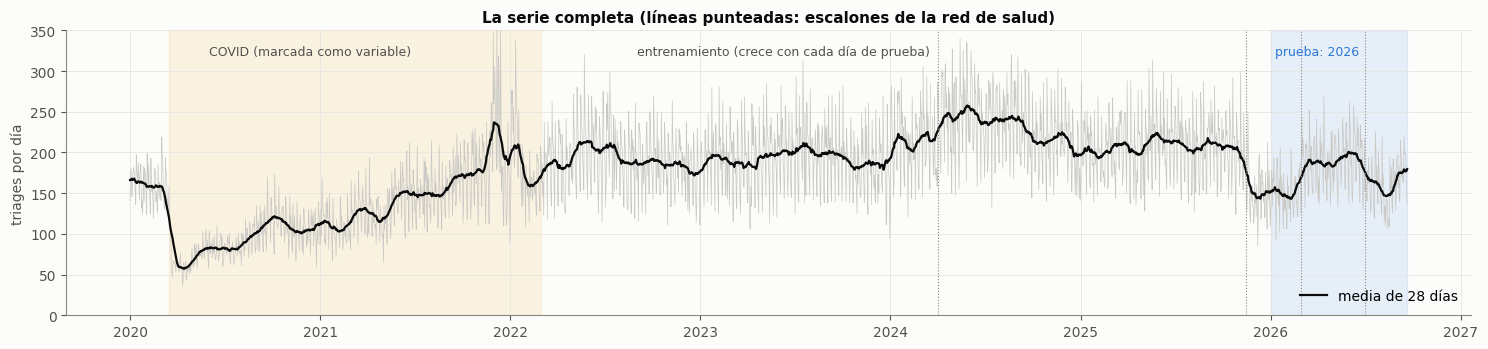

In [2]:
disp = pd.DataFrame([
    ["Triage diario", "salidas/triage_diario.parquet", "hasta el día de la predicción", "nivel y memoria"],
    ["Calendario de Colombia", "calendario_Colombia.csv", "por adelantado", "calendario"],
    ["COVID (dos fases)", "fechas fijas", "por adelantado", "calendario"],
    ["Feria, eventos de Manizales, fiestas de Caldas, días especiales", "eventos_*, fiestas_*, calendario", "por adelantado (programados)", "eventos"],
    ["IRA de Manizales (total, 0-4, 60+), consultas por toda causa", "Power BI 995 + microdatos", "semana epidemiológica anterior", "salud"],
    ["Agresión animal, intento de suicidio, varicela, violencia de género, intoxicaciones", "Power BI + microdatos", "semana anterior", "salud"],
    ["Temperatura, humedad, lluvia, radiación, viento (anomalías de 7 y 28 días)", "clima_unificado.csv.gz", "hasta el día anterior", "clima"],
    ["Lesiones de tránsito, lesiones personales, homicidio, violencia intrafamiliar", "seguridad_mindefensa.csv.gz", "hasta el día anterior", "social"],
    ["Nueva EPS: cambio de 28 días y peso en el triage", "triage_entidad.parquet", "hasta el día de la predicción", "red"],
    ["Desastre activo (incluye el terremoto del 10-08-2026)", "desastres_manizales_2020_2026.csv", "cuando ya empezó", "catástrofe"],
    ["ENSO (El Niño / La Niña)", "enso_oni.csv", "con dos meses de retraso", "ENSO"],
    ["Clima o IRA de los días que vienen", "—", "NO se sabe (no hay archivo histórico de pronósticos)", "no se usa"],
], columns=["dato", "fuente", "¿cuándo se sabe?", "capa"])
display(disp)

fig, ax = plt.subplots(figsize=(15, 3.6))
ax.plot(y.index, y.values, color="#c9c8c4", lw=.5)
ax.plot(y.index, y.rolling(28, center=True, min_periods=14).mean(), color=TINTA, lw=1.6, label="media de 28 días")
ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2022-02-28"), color=AMARILLO, alpha=.10)
ax.axvspan(pd.Timestamp("2026-01-01"), y.index[-1], color=AZUL, alpha=.10)
ax.text(pd.Timestamp("2020-06-01"), 320, "COVID (marcada como variable)", color=TINTA2, fontsize=9)
ax.text(pd.Timestamp("2026-01-10"), 320, "prueba: 2026", color=AZUL, fontsize=9)
ax.text(pd.Timestamp("2022-09-01"), 320, "entrenamiento (crece con cada día de prueba)", color=TINTA2, fontsize=9)
for f in ["2024-04-01", "2025-11-15", "2026-03-01", "2026-07-01"]: ax.axvline(pd.Timestamp(f), color=MUDO, lw=.8, ls=":")
ax.set_ylim(0, 350); ax.set_ylabel("triages por día"); ax.legend(loc="lower right")
ax.set_title("La serie completa (líneas punteadas: escalones de la red de salud)"); plt.tight_layout(); plt.show()

**Lectura.** El modelo entrena con 2020-2025 y se prueba en 2026, un año que nunca vio.

- **La COVID va marcada** como dos fases, para que el modelo no confunda el cráter de 2020 con la forma normal del hospital.
- **2026 es un año difícil a propósito.** Trae escalones de Nueva EPS (marzo y julio) y un terremoto (10 de agosto). El hospital no avisa esos cambios con antelación, y por eso es la prueba más honesta posible.
- **Lo que no se sabe al predecir no entra.** El clima o la IRA de los días que vienen no se conocen, y no hay archivo histórico de pronósticos.

---
# 2. Las entradas, por capas

Cada capa es una razón posible de que un día tenga más o menos triage. Es lo que permite decir **por
qué** se mueve la predicción.

In [3]:
X2 = pr.rasgos(y, cal.reindex(y.index), 1, tuple(c.reindex(y.index) for c in pr.contexto(cal.index)))
capa = pd.Series(pr.capas(X2.columns))
resumen = capa.value_counts().rename("variables").to_frame()
resumen["ejemplos"] = [", ".join(capa[capa == k].index[:3]) for k in resumen.index]
print(f"{X2.shape[1]} entradas por día en E2")
resumen

77 entradas por día en E2


,variables,ejemplos
eventos,20,"fut_ev_feria, fut_ev_religioso, fut_ev_civico"
calendario,18,"dow_1, dow_2, dow_3"
clima,12,"ext_cli_temp_7d, ext_cli_temp_28d, ext_cli_tmi..."
salud,9,"ext_sal_ira_total, ext_sal_ira_0_4, ext_sal_ir..."
estacion,6,"four_s1, four_c1, four_s2"
social,4,"ext_soc_lesiones_transito, ext_soc_lesiones_pe..."
memoria,3,"mem_semana, mem_ultimo, mem_mismo_dia"
red,2,"ext_red_nueva_cambio, ext_red_nueva_peso"
nivel,1,nivel
catastrofe,1,ext_cat_desastre


**Lectura.** En E2 cada día llega con **77 entradas**:

- 28 internas: calendario, estación, nivel y memoria;
- 49 externas: salud, clima, social, red de salud, catástrofes, ENSO y eventos.

E3 se queda solo con las **8 externas** que un modelo entrenado hasta 2025 encontró más útiles (fila `contexto_depurado`):

- IRA y consultas totales;
- cambio de la radiación y temperatura del mes;
- lesiones personales y violencia intrafamiliar;
- peso y cambio de Nueva EPS.

---
# 3. Los modelos

| Modelo | Técnica | Cómo da la distribución | Ventaja | Riesgo |
|---|---|---|---|---|
| **Ingenuo** | base | lo de hace 7 días × su dispersión | nada que ajustar | no ve nada más |
| **Control** | base | calendario + nivel, en log | es la vara del proyecto | no ve estación ni contexto |
| **Regresión binomial negativa** | regresión de conteo | cada factor multiplica | **da las razones** directo | supone efectos que solo se suman en log |
| **LightGBM** | árboles con refuerzo | un modelo por cuantil | capta interacciones | se sobreajusta con pocos datos |
| **SARIMAX** | serie de tiempo clásica | error gaussiano del log, que crece con el horizonte | **se actualiza cada día** con lo que acaba de pasar | lineal |
| **Prophet** | serie de tiempo por componentes | simulación | buena para estaciones largas | no tiene memoria de corto plazo |
| **Chronos-2** | modelo fundacional de series (IA preentrenada) | cuantiles directos | **no se entrena con estos datos** | caja negra y lento con muchas covariables |
| **MedGemma** | modelo de lenguaje médico | un solo número (no da distribución) | — | no está hecho para series |

**Detalles que cuentan:**
- Todos se reentrenan cada 7 días con todo lo anterior.
- Ningún parámetro se eligió mirando 2026.

---
# 4. Cómo se mide, en simple

| Criterio | Qué pregunta contesta | Cómo se lee |
|---|---|---|
| **Acierta si sube o baja** | ¿El día quedó por encima o por debajo de lo que anunciaba el calendario, como dijo el modelo? | 50 % = adivinar. **La meta es 60-70 %** |
| **Mejora de la probabilidad (BSS)** | ¿Su «60 % de que suba» vale más que decir siempre la tasa normal? | Positivo: sirve. Negativo: peor que no tener modelo |
| **Desvío anticipado (R²)** | De lo que el calendario no explica, ¿cuánto vio venir? | 0 % = no sabe más que el calendario |
| **Cobertura del 80 %** | De cada 100 días, ¿cuántos cayeron dentro del rango que prometió con 80 % de seguridad? | **75-85 % = honesto.** Menos es exceso de confianza (sobreajuste) |
| Días con error ≤ 10 % y MAPE | ¿Qué tan cerca quedó el número? | Para comunicar; casi todo lo explica el calendario |

**Deciden la mejora de la probabilidad y la cobertura.** El MAPE solo comunica: un modelo puede
clavar los lunes y no anticipar nada.

---
# 5. Prueba 1: corto plazo, cada día de 2026

## 5.1 Los tres experimentos, modelo por modelo

BSS pico %                   BSS sube %        \
exp                                  e0    e1    e2    e3         e0    e1   
modelo_                                                                      
SARIMAX (serie de tiempo)          14.2  13.3   NaN  12.2       17.2  18.8   
Chronos-2 (IA de series)           11.9  13.1   NaN  12.9        9.6  12.1   
LightGBM (árboles)                 -0.2  11.4   5.2   3.9        1.6  15.9   
Regresión binomial negativa         8.1  11.1   6.2   8.7        9.1  14.5   
Chronos-2 solo                      4.6   NaN   NaN   NaN        5.4   NaN   
Control (calendario + nivel)       -0.7   NaN   NaN   NaN       -0.2   NaN   
Ingenuo (semana pasada)           -14.6   NaN   NaN   NaN       -3.7   NaN   
Prophet (serie de tiempo)         -30.6 -33.0 -12.4   NaN      -38.7 -35.1   

                                         MAPE %                    \
exp                             e2    e3     e0    e1    e2    e3   
modelo_                                                             
SARIMAX (serie de tiempo)      NaN  16.3    9.2   9.0   NaN   9.1   
Chronos-2 (IA de series)       NaN  13.3    9.9   9.6   NaN   9.5   
LightGBM (árboles)             6.4   8.5   11.1   9.8  10.7  10.4   
Regresión binomial negativa    6.3  11.0   10.0   9.5  10.2   9.9   
Chronos-2 solo                 NaN   NaN   10.8   NaN   NaN   NaN   
Control (calendario + nivel)   NaN   NaN   10.9   NaN   NaN   NaN   
Ingenuo (semana pasada)        NaN   NaN   13.3   NaN   NaN   NaN   
Prophet (serie de tiempo)    -17.1   NaN   12.8  13.9  11.7   NaN   

                             acierta sube/baja %                   cob80 %  \
exp                                           e0    e1    e2    e3      e0   
modelo_                                                                      
SARIMAX (serie de tiempo)                   65.7  66.8   NaN  65.0    80.4   
Chronos-2 (IA de series)                    62.6  65.6   NaN  65.4    81.5   
LightGBM (árboles)                          60.4  67.8  62.6  64.9    70.7   
Regresión binomial negativa                 64.3  65.0  59.9  62.5    79.0   
Chronos-2 solo                              64.2   NaN   NaN   NaN    81.5   
Control (calendario + nivel)                52.4   NaN   NaN   NaN    69.3   
Ingenuo (semana pasada)                     56.8   NaN   NaN   NaN    79.2   
Prophet (serie de tiempo)                   41.0  42.7  52.0   NaN    55.9   

                                                
exp                             e1    e2    e3  
modelo_                                         
SARIMAX (serie de tiempo)     85.4   NaN  84.5  
Chronos-2 (IA de series)      79.4   NaN  81.8  
LightGBM (árboles)            71.2  73.0  74.0  
Regresión binomial negativa   84.0  78.4  82.7  
Chronos-2 solo                 NaN   NaN   NaN  
Control (calendario + nivel)   NaN   NaN   NaN  
Ingenuo (semana pasada)        NaN   NaN   NaN  
Prophet (serie de tiempo)     61.3  69.4   NaN

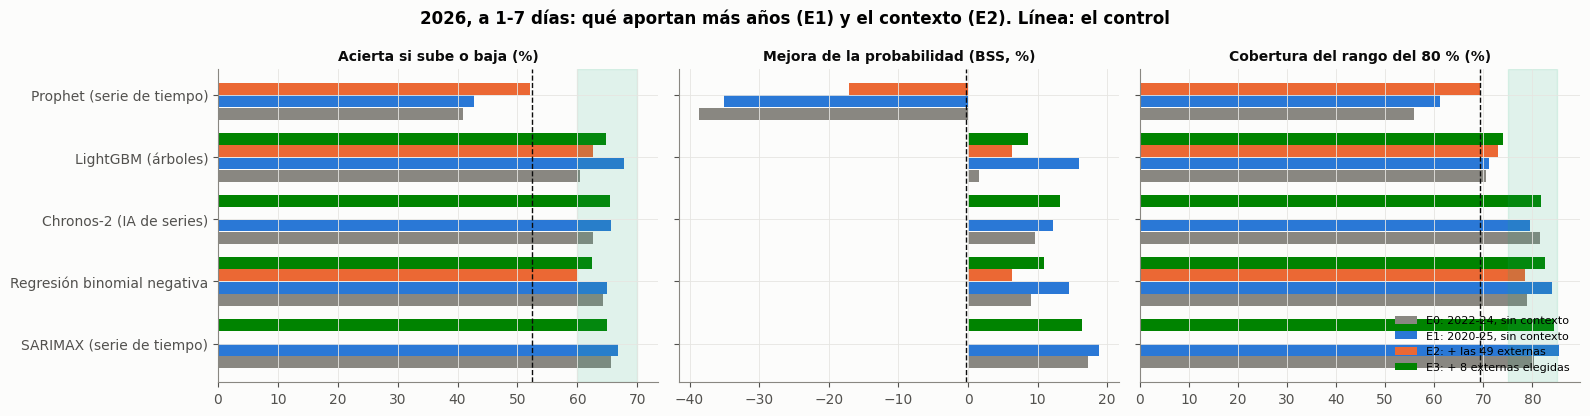

In [4]:
tablas = []
for e in ["e0", "e1", "e2", "e3"]:
    P, U = leer(e)
    P2, T = pr.metricas(P, U)
    tablas.append(T.assign(exp=e).reset_index())
R = pd.concat(tablas)
R["modelo_"] = R.modelo.map(NOMBRE)
tab = R.pivot_table(index="modelo_", columns="exp", values=["acierta sube/baja %", "BSS sube %", "BSS pico %", "cob80 %", "MAPE %"])
tab = tab.reindex(tab[("BSS sube %", "e2")].fillna(tab[("BSS sube %", "e0")]).sort_values(ascending=False).index)
display(tab.round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
mods = [m for m in ["sarimax", "glm_binneg", "chronos2_cal", "lightgbm", "prophet"] if m in set(R.modelo)]
for ax, (c, t) in zip(axes, [("acierta sube/baja %", "Acierta si sube o baja (%)"), ("BSS sube %", "Mejora de la probabilidad (BSS, %)"), ("cob80 %", "Cobertura del rango del 80 % (%)")]):
    for j, e in enumerate(["e0", "e1", "e2", "e3"]):
        v = R[R.exp == e].set_index("modelo").reindex(mods)[c]
        ax.barh(np.arange(len(mods)) + (j - 1.5) * .2, v.values, height=.19, color=[MUDO, AZUL, NARANJA, VERDE][j],
                label={"e0": "E0: 2022-24, sin contexto", "e1": "E1: 2020-25, sin contexto", "e2": "E2: + las 49 externas", "e3": "E3: + 8 externas elegidas"}[e])
    ax.set_title(t, fontsize=10)
    base = R[(R.exp == "e0") & (R.modelo == "control")][c].iloc[0]
    ax.axvline(base, color=TINTA, lw=1, ls="--")
axes[0].set_yticks(range(len(mods)), [NOMBRE[m] for m in mods]); axes[2].axvspan(75, 85, color=AQUA, alpha=.12)
axes[0].axvspan(60, 70, color=AQUA, alpha=.12)
axes[2].legend(fontsize=8, loc="lower right"); fig.suptitle("2026, a 1-7 días: qué aportan más años (E1) y el contexto (E2). Línea: el control", fontweight="bold")
plt.tight_layout(); plt.show()

**Lectura.** En 2026, a 1-7 días:

1. **Más años de historia es lo que más mejora a todos.** De E0 a E1:
   - LightGBM pasa de +1,6 % a **+15,9 %** de mejora en la probabilidad;
   - la regresión, de +9,1 % a +14,5 %;
   - SARIMAX, de +17,2 % a **+18,8 %**.
2. **El contexto externo no mejora la predicción del total.**
   - Con las 49 variables (E2), la regresión y LightGBM empeoran: es sobreajuste.
   - Con las 8 elegidas (E3) empeoran menos, pero tampoco superan a E1. SARIMAX E3 es significativamente peor en la probabilidad (p = 0,002).
   - Chronos-2 es la excepción: el contexto le suma +1,2 puntos, dentro del ruido.
3. **Prophet queda por debajo del control en todas las versiones.** Le falta memoria de corto plazo.

## 5.2 Chronos-2 con todo el contexto

Con 61 covariables, Chronos-2 en CPU tarda horas por cada origen diario. Se corrió con **un origen
cada 7 días** (37 orígenes de 2026). La información es la misma; solo hay menos predicciones.
Para compararlo de forma justa, **todos los modelos se miden en esos mismos 37 orígenes**.

In [5]:
P7, U7 = pr.leer(exp="e2")
cada7 = sorted(P7[P7.modelo.str.endswith("_cada7")].origen.unique())
if cada7:
    partes = [P7[P7.modelo.str.endswith("_cada7")].assign(modelo=lambda d: d.modelo + " · e2")]
    for e in ["e0", "e1", "e2", "e3"]:
        P, _ = leer(e); partes.append(P[P.origen.isin(cada7)].assign(modelo=lambda d, e=e: d.modelo + " · " + e))
    _, T7 = pr.metricas(pd.concat(partes), U7)
    display(T7[CRIT].sort_values("BSS sube %", ascending=False).round(1))
else:
    print("Chronos-2 con contexto todavía no ha terminado.")

,BSS sube %,BSS pico %,R2 desvio %,acierta sube/baja %,AUC pico,cob80 %,error <=10 %,MAPE %,n
modelo,,,,,,,,,
sarimax · e1,17.4,11.3,25.2,62.9,0.7,85.3,66.8,9.1,259.0
lightgbm · e1,17.0,7.2,16.0,66.0,0.7,73.4,61.8,9.7,259.0
sarimax · e0,16.3,12.9,24.8,66.0,0.8,80.7,64.1,9.2,259.0
chronos2_cal_cada7 · e2,15.9,11.7,18.1,70.3,0.8,78.8,65.3,9.5,259.0
sarimax · e3,15.5,10.7,24.0,60.6,0.7,84.9,65.3,9.2,259.0
glm_binneg · e1,13.7,9.4,18.9,64.5,0.7,83.8,64.9,9.6,259.0
chronos2_cal · e3,13.1,13.6,19.7,66.8,0.8,80.7,64.9,9.4,259.0
chronos2_cal · e1,12.8,12.4,18.5,68.0,0.8,77.6,65.3,9.5,259.0
glm_binneg · e3,11.3,8.3,16.8,61.0,0.7,82.6,62.2,9.8,259.0


**Lectura.** En los mismos 37 orígenes, Chronos-2 con todo el contexto acierta el 70 % si el día sube o baja. Con su probabilidad (+15,9 %) **no se distingue de SARIMAX ni de LightGBM**: con 37 orígenes, la incertidumbre es de ±7 puntos.

Con los 257 orígenes y las 8 variables externas (E3), Chronos queda en 65,4 % y +13,3 %. La mejora frente a E0 viene sobre todo de tener más años.

## 5.3 El jerárquico: Nueva EPS y el resto por separado

Nueva EPS (58 % del triage) salta a escalones que el resto no tiene. Se predice cada parte con el mismo
modelo y las entradas de E1, y se arma el total de dos formas, preregistradas (filas `jerarquico` y
`jerarquico_correlado` de `variables.csv`):
- **suma de cuantiles:** supone que las dos partes se mueven siempre juntas;
- **cópula:** usa la correlación real entre las dos, medida en enero de 2026 y congelada.

In [6]:
from scipy.stats import spearmanr, norm
CORTE = pd.Timestamp("2026-01-28")
def jerarquico(modelo, metodo):
    a, _ = pr.leer([modelo], exp="j_ne"); b, _ = pr.leer([modelo], exp="j_resto")
    m = a.merge(b, on=["origen", "h", "fecha"], suffixes=("_ne", "_re"))
    c0 = m[(m.origen < CORTE) & (m.h == 1)].dropna(subset=["real_ne", "real_re"])
    rho = spearmanr(np.log(c0.real_ne / c0.q50_ne), np.log(c0.real_re / c0.q50_re))[0]
    out = m[["origen", "h", "fecha"]].copy(); out["modelo"] = f"{NOMBRE[modelo]} · jerárquico ({metodo})"
    if metodo == "suma":
        for c in pr.QCOL: out[c] = m[c + "_ne"] + m[c + "_re"]
    else:
        u = norm.cdf(np.random.default_rng(0).multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=4000))
        Qa, Qb = m[[c + "_ne" for c in pr.QCOL]].values, m[[c + "_re" for c in pr.QCOL]].values
        tot = np.array([np.quantile(np.interp(u[:, 0], pr.QL, x) + np.interp(u[:, 1], pr.QL, z), pr.QL) for x, z in zip(Qa, Qb)])
        for j, c in enumerate(pr.QCOL): out[c] = tot[:, j]
    return out, rho
P1, U1 = leer("e1"); real = P1[["fecha", "real"]].drop_duplicates("fecha")
lista = []
for mod in ["sarimax", "glm_binneg"]:
    for metodo in ["suma", "cópula"]:
        o, rho = jerarquico(mod, metodo); lista.append(o.merge(real, on="fecha"))
    lista.append(P1[P1.modelo == mod].assign(modelo=NOMBRE[mod] + " · sobre el total"))
    print(f"{NOMBRE[mod]}: correlación de Spearman entre Nueva EPS y el resto, en enero = {rho:.2f}")
_, TJ = pr.metricas(pd.concat(lista), U1)
display(TJ[CRIT].sort_values("BSS sube %", ascending=False).round(1))
a, _ = pr.leer(["sarimax"], exp="j_ne"); a = a[a.h == 1]
print("Nueva EPS en 2026: media real por mes y predicción de SARIMAX a 1 día")
display(a.groupby(a.fecha.dt.month)[["real", "q50"]].mean().round(0).T)

SARIMAX (serie de tiempo): correlación de Spearman entre Nueva EPS y el resto, en enero = 0.33


Regresión binomial negativa: correlación de Spearman entre Nueva EPS y el resto, en enero = 0.35


,BSS sube %,BSS pico %,R2 desvio %,acierta sube/baja %,AUC pico,cob80 %,error <=10 %,MAPE %,n
modelo,,,,,,,,,
SARIMAX (serie de tiempo) · sobre el total,18.8,13.3,27.1,66.8,0.8,85.4,65.3,9.0,1799.0
SARIMAX (serie de tiempo) · jerárquico (cópula),18.1,12.7,27.9,67.6,0.8,88.8,65.9,8.9,1799.0
SARIMAX (serie de tiempo) · jerárquico (suma),17.1,10.8,27.3,67.9,0.8,92.9,65.0,8.9,1799.0
Regresión binomial negativa · sobre el total,14.5,11.1,20.5,65.0,0.7,84.0,63.0,9.5,1799.0
Regresión binomial negativa · jerárquico (cópula),14.0,10.0,22.2,66.6,0.7,87.5,63.3,9.4,1799.0
Regresión binomial negativa · jerárquico (suma),13.5,7.6,22.7,66.4,0.7,92.6,62.5,9.3,1799.0


Nueva EPS en 2026: media real por mes y predicción de SARIMAX a 1 día


fecha,1,2,3,4,5,6,7,8,9
real,57.0,53.0,89.0,93.0,91.0,95.0,52.0,52.0,68.0
q50,58.0,52.0,82.0,94.0,91.0,97.0,56.0,51.0,66.0


**Lectura.** Separar Nueva EPS del resto:

- **Mejora un poco la dirección y el número.** SARIMAX pasa de 66,8 % a 67,6 % de acierto y de 27,1 % a 27,9 % de desvío anticipado.
- **Ensancha el rango.** Con la suma de cuantiles se cumple el 92,9 % cuando promete 80 %; con la cópula, que usa la correlación de 0,33 medida en enero, el 88,8 %.
- **SARIMAX jerárquico y SARIMAX sobre el total quedan empatados**: la incertidumbre de un acierto con 257 días es de ±3 puntos.

El valor del jerárquico es **explicativo**. La tabla de Nueva EPS lo muestra:

- **Nueva EPS salta a escalones**: ~55 triages por día en enero y febrero, **~92 de marzo a junio**, ~52 en julio y agosto.
- SARIMAX los sigue en pocos días, pero no los anticipa.
- Es la variable institucional que falta (pendiente #11 del `HANDOFF`).

## 5.4 La vara justa: seguir el nivel no es anticipar el día

El control de calendario usa el nivel de los últimos 28 días. Cuando Nueva EPS salta (marzo, julio,
septiembre), queda corrido un 10-13 % durante semanas, y cualquier modelo que se adapte rápido «acierta».
Por eso hay una **segunda vara**, el **control rápido**: calendario + nivel de 28 días + desvío de la
última semana (fila `control_rapido` de `variables.csv`).

**Cómo se lee:**
- con la vara de 28 días se mide **seguir el nivel de la red**;
- con la rápida, **anticipar el día**;
- en los meses estables (abril-junio) la vara justa es la de 28 días, porque la rápida persigue la
  última semana, que luego se revierte.

In [7]:
def tabla_varas(lista):
    partes = []
    for e, ms in lista:
        P, _ = pr.leer(ms, exp=e); partes.append(P[P.origen >= "2025-12-31"].assign(modelo=lambda d, e=e: NOMBRE.get(d.modelo.iloc[0], d.modelo.iloc[0]) + " · " + e))
    Pall = pd.concat(partes); res = {}
    for vara, nom in [("calendario", "vara de 28 días"), ("rapido", "vara rápida")]:
        _, U = pr.leer(["control"], exp="e0", vara=vara)
        _, T = pr.metricas(Pall, U); _, Te = pr.metricas(Pall[Pall.fecha.dt.month.isin([4, 5, 6])], U)
        res[nom] = pd.DataFrame({"acierta %": T["acierta sube/baja %"], "BSS sube %": T["BSS sube %"], "BSS pico %": T["BSS pico %"],
                                 "acierta abr-jun %": Te["acierta sube/baja %"], "BSS abr-jun %": Te["BSS sube %"]})
    R = pd.concat(res, axis=1)
    R[("rango y error", "cob80 %")] = T["cob80 %"]; R[("rango y error", "MAPE %")] = T["MAPE %"]
    return R.sort_values(("vara de 28 días", "BSS sube %"), ascending=False).round(1)
lista = [("e1", [m]) for m in ["sarimax", "lightgbm", "glm_binneg", "chronos2_cal", "lightgbm_afinado", "xgboost_afinado", "gbr_afinado", "comb_sarimax_lightgbm", "comb_4_modelos"]]
lista += [("e3", ["sarimax"]), ("e3", ["chronos2_cal"]), ("e3", ["lightgbm"])]
TV = tabla_varas(lista); TV

vara de 28 días                        \
                                            acierta % BSS sube % BSS pico %   
modelo                                                                        
SARIMAX + LightGBM (combinación) · e1            69.4       21.1       16.5   
Combinación de 4 modelos · e1                    68.9       19.3       17.3   
SARIMAX (serie de tiempo) · e1                   66.8       18.8       13.3   
SARIMAX (serie de tiempo) · e3                   65.0       16.3       12.2   
LightGBM (árboles) · e1                          67.8       15.9       11.4   
Regresión binomial negativa · e1                 65.0       14.5       11.1   
Chronos-2 (IA de series) · e3                    65.4       13.3       12.9   
LightGBM afinado · e1                            66.7       13.1        8.6   
Chronos-2 (IA de series) · e1                    65.6       12.1       13.1   
XGBoost afinado · e1                             65.0       11.6       10.7   
GradientBoosting afinado · e1                    64.5       10.3        8.0   
LightGBM (árboles) · e3                          64.9        8.5        3.9   

                                                                       \
                                      acierta abr-jun % BSS abr-jun %   
modelo                                                                  
SARIMAX + LightGBM (combinación) · e1              58.6           5.9   
Combinación de 4 modelos · e1                      57.5           3.5   
SARIMAX (serie de tiempo) · e1                     50.2           0.1   
SARIMAX (serie de tiempo) · e3                     49.8          -3.1   
LightGBM (árboles) · e1                            63.3           7.4   
Regresión binomial negativa · e1                   50.2          -5.6   
Chronos-2 (IA de series) · e3                      52.7          -3.9   
LightGBM afinado · e1                              61.1           2.6   
Chronos-2 (IA de series) · e1                      55.7          -2.6   
XGBoost afinado · e1                               56.8           0.8   
GradientBoosting afinado · e1                      56.7          -2.0   
LightGBM (árboles) · e3                            54.5          -5.4   

                                      vara rápida                        \
                                        acierta % BSS sube % BSS pico %   
modelo                                                                    
SARIMAX + LightGBM (combinación) · e1        64.1        9.3        5.2   
Combinación de 4 modelos · e1                63.5        8.1        6.3   
SARIMAX (serie de tiempo) · e1               60.5        8.1        3.5   
SARIMAX (serie de tiempo) · e3               59.5        5.9        3.5   
LightGBM (árboles) · e1                      61.1        1.1       -3.9   
Regresión binomial negativa · e1             58.1        3.2       -0.2   
Chronos-2 (IA de series) · e3                58.9        2.3        1.4   
LightGBM afinado · e1                        59.8        0.3      -11.8   
Chronos-2 (IA de series) · e1                59.3        1.2        0.5   
XGBoost afinado · e1                         59.9        0.3       -4.7   
GradientBoosting afinado · e1                59.8       -1.5       -7.5   
LightGBM (árboles) · e3                      56.6       -5.5       -8.1   

                                                                       \
                                      acierta abr-jun % BSS abr-jun %   
modelo                                                                  
SARIMAX + LightGBM (combinación) · e1              64.7           9.4   
Combinación de 4 modelos · e1                      61.2           6.3   
SARIMAX (serie de tiempo) · e1                     54.2           2.2   
SARIMAX (serie de tiempo) · e3                     53.1          -1.0   
LightGBM (árboles) · e1                            67.2          11.9   
Regresión binomial negativa · e1              

**Lectura.** La tabla tiene dos varas, y la diferencia entre ellas es el hallazgo de método más importante de este cuaderno.

- **Con la vara de 28 días los modelos «aciertan» 65-69 %**, pero casi todo es **seguir los escalones de Nueva EPS** más rápido que el control. En marzo, julio y septiembre cualquier modelo ágil acierta 80-90 %.
- **Con la vara rápida, la cifra honesta de «anticipar el día» es ~60-64 %:**
  - la combinación SARIMAX + LightGBM, **64,1 %**;
  - SARIMAX, 60,5 %;
  - LightGBM, 61,1 %.
- **En los meses estables (abril-junio, vara de 28 días), solo los árboles ven algo:** LightGBM 63,3 % y la combinación 58,6 %, frente a ~50 % de SARIMAX, la regresión y Chronos.
- **La combinación SARIMAX + LightGBM es la mejor en casi todo:**
  - 69,4 % de acierto;
  - +21,1 % de mejora en la probabilidad de «sube» y +16,5 % en la de pico;
  - **el rango del 80 % se cumple el 80,3 % de las veces**;
  - 8,9 % de error.
- **Afinar los árboles no los mejoró** en 2026, aunque sí mejoró sus rangos (71 → 77 %).

## 5.5 ¿Hay un ganador de verdad? Pruebas de significancia

Cada modelo se compara contra SARIMAX día por día. Se remuestrea 2.000 veces por bloques de 7 orígenes
(conserva la dependencia entre días cercanos) para obtener el intervalo del 95 % de la diferencia. **Si el
intervalo cruza el cero, es un empate.**

In [8]:
P, U = pr.leer(["sarimax", "lightgbm", "glm_binneg", "chronos2_cal", "comb_sarimax_lightgbm"], exp="e1")
P = P[P.origen >= "2025-12-31"]; _, U = pr.leer(["control"], exp="e0")
PS, _ = pr.metricas(P, U)
PS["acierta"] = ((PS.p_sobre > .5) == (PS.sobre == 1)).astype(float) * 100
PS["brier x1000"] = (PS.p_sobre - PS.sobre) ** 2 * 1000
PS["error %"] = (PS.q50 - PS.real).abs() / PS.real * 100
rng = np.random.default_rng(0); filas = []
for sub, D in [("todo 2026", PS), ("abril-junio", PS[PS.fecha.dt.month.isin([4, 5, 6])])]:
    for m in ["lightgbm", "chronos2_cal", "glm_binneg", "comb_sarimax_lightgbm"]:
        for col, mayor in [("acierta", True), ("brier x1000", False), ("error %", False)]:
            w = D.pivot_table(index=["origen", "h"], columns="modelo", values=col)[["sarimax", m]].dropna()
            d = (w[m] - w["sarimax"]).groupby(level=0).mean(); g = np.arange(len(d)) // 7
            G = [np.where(g == x)[0] for x in np.unique(g)]
            B = np.array([d.values[np.concatenate([G[j] for j in rng.integers(0, len(G), len(G))])].mean() for _ in range(2000)])
            lo, hi = np.percentile(B, [2.5, 97.5])
            filas.append({"periodo": sub, "modelo": NOMBRE[m], "criterio": col, "modelo − SARIMAX": round(d.mean(), 2),
                          "IC 95 %": f"[{lo:.2f}, {hi:.2f}]",
                          "resultado": "empate" if lo <= 0 <= hi else (f"gana {NOMBRE[m]}" if (d.mean() > 0) == mayor else "gana SARIMAX")})
pd.DataFrame(filas)

,periodo,modelo,criterio,modelo − SARIMAX,IC 95 %,resultado
0,todo 2026,LightGBM (árboles),acierta,0.94,"[-6.17, 7.67]",empate
1,todo 2026,LightGBM (árboles),brier x1000,7.30,"[-12.95, 28.51]",empate
2,todo 2026,LightGBM (árboles),error %,0.78,"[0.05, 1.59]",gana SARIMAX
3,todo 2026,Chronos-2 (IA de series),acierta,-1.22,"[-5.94, 3.56]",empate
4,todo 2026,Chronos-2 (IA de series),brier x1000,16.66,"[0.25, 33.25]",gana SARIMAX
5,todo 2026,Chronos-2 (IA de series),error %,0.59,"[0.04, 1.16]",gana SARIMAX
6,todo 2026,Regresión binomial negativa,acierta,-1.83,"[-5.60, 2.02]",empate
7,todo 2026,Regresión binomial negativa,brier x1000,10.80,"[0.82, 21.34]",gana SARIMAX
8,todo 2026,Regresión binomial negativa,error %,0.56,"[0.16, 0.96]",gana SARIMAX
9,todo 2026,SARIMAX + LightGBM (combinación),acierta,2.61,"[-0.39, 5.93]",empate


**Lectura.** Esta tabla responde a la pregunta del propietario: ¿SARIMAX es de verdad el mejor, o se le estaba dando ventaja?

- **En acertar si sube o baja, todos empatan con SARIMAX.** Ninguna diferencia sale del intervalo.
- **SARIMAX gana con significancia en dos cosas pequeñas:**
  - el error del número, por 0,5-0,8 puntos;
  - la calidad de la probabilidad, frente a Chronos y la regresión. Frente a LightGBM, empata.
- **En abril-junio, LightGBM le saca +10 puntos de acierto**, justo en el borde de lo significativo.
- **La combinación SARIMAX + LightGBM es la única que mejora a SARIMAX con significancia:** en los meses estables, +7,8 puntos de acierto y un Brier 13,5 menor. Frente a LightGBM, su probabilidad también es significativamente mejor.

Llamar a SARIMAX «el mejor» exageraba un empate. **El líder es la combinación.**

## 5.6 LazyPredict y los árboles afinados

**LazyPredict** ajustó de una vez 42 regresores de scikit-learn, más XGBoost y LightGBM, con sus parámetros
por defecto. Se entrenaron hasta el 31-12-2025, quedaron congelados y se probaron en 2026, a 1 día
(`notebooks/lazypredict_barrido.py`).

Los **árboles afinados** (`notebooks/arboles.py`) siguen tres etapas:
- se afinan con 2024;
- calibran su rango con los errores reales de 2025;
- se prueban en 2026 con origen rodante.

In [9]:
import json
for e in ["e1", "e3"]:
    L = pd.read_csv(pr.SALIDA / f"lazypredict_{e}.csv", index_col=0)
    print(f"LazyPredict, entradas {e} ({'triage + calendario' if e == 'e1' else '+ 8 externas'}): 10 primeros de {len(L)}")
    display(L[["acierta sube/baja %", "acierta abr-jun %", "MAPE %", "R-Squared"]].head(10).round(1))
cfg = {f: json.loads((pr.SALIDA / "e1" / f"_afinado_{f}_etapas.json").read_text(encoding="utf-8"))["elegida"] for f in ["xgboost", "gbr", "lightgbm"]}
pd.Series(cfg, name="configuración elegida con 2024").to_frame()

LazyPredict, entradas e1 (triage + calendario): 10 primeros de 42


,acierta sube/baja %,acierta abr-jun %,MAPE %,R-Squared
Model,,,,
GradientBoostingRegressor,67.3,60.4,9.3,0.6
LGBMRegressor,66.9,58.2,9.2,0.7
RidgeCV,66.1,53.8,8.7,0.7
LinearRegression,66.1,53.8,8.7,0.7
TransformedTargetRegressor,66.1,53.8,8.7,0.7
ElasticNetCV,66.1,53.8,8.6,0.7
LassoLarsCV,66.1,53.8,8.7,0.7
LassoCV,66.1,53.8,8.6,0.7
Ridge,66.1,53.8,8.7,0.7


LazyPredict, entradas e3 (+ 8 externas): 10 primeros de 42


,acierta sube/baja %,acierta abr-jun %,MAPE %,R-Squared
Model,,,,
ElasticNetCV,63.0,54.9,9.2,0.7
LassoLarsIC,63.0,54.9,9.2,0.7
LassoLarsCV,62.6,53.8,9.0,0.7
LassoCV,62.6,53.8,9.0,0.7
LarsCV,62.6,53.8,9.0,0.7
TransformedTargetRegressor,62.3,52.7,9.4,0.7
LinearRegression,62.3,52.7,9.4,0.7
Lars,62.3,52.7,9.4,0.7
HuberRegressor,62.3,52.7,9.5,0.7


,configuración elegida con 2024
xgboost,"{'max_depth': 2, 'n_estimators': 500, 'learnin..."
gbr,"{'max_depth': 3, 'n_estimators': 500, 'learnin..."
lightgbm,"{'num_leaves': 15, 'min_child_samples': 20, 'n..."


**Lectura.**

- **LazyPredict, entradas de E1:**
  - **los primeros son ensambles de árboles**: GradientBoosting 67,3 % de acierto (60,4 % en abril-junio) y LightGBM 66,9 %;
  - les sigue la familia lineal (66,2 %, pero 54 % en abril-junio);
  - **XGBoost con su configuración de fábrica se sobreajusta** (62,6 %);
  - los peores son GaussianProcess, KernelRidge, KNN y la red neuronal MLP, con ~50 %: no sirven con estos datos sin preparación.
- **LazyPredict, entradas de E3:** los 42 modelos empeoran con las 8 variables externas.
- **Los árboles afinados eligieron en 2024 árboles poco profundos** (XGBoost con profundidad 2; GradientBoosting con 3). Eso apunta a señal simple.
- **Afinar no mejoró ningún árbol en 2026.** La mejor configuración de 2024 no fue la mejor de 2026, que es otro régimen (Nueva EPS).

## 5.7 ¿Se puede creer la probabilidad? Calibración del mejor de cada familia

Se agrupan los días por la probabilidad de «sube» que dio el modelo, y se mira cuántas veces subió
de verdad. Un modelo calibrado cae sobre la diagonal.

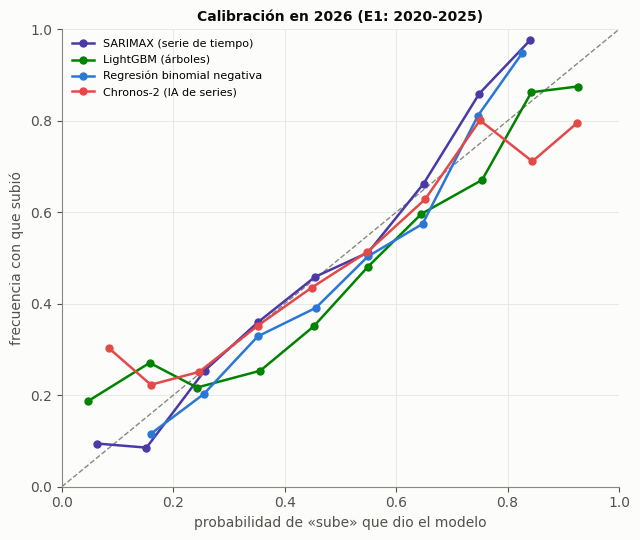

In [10]:
P, U = leer("e1"); P2, T2 = pr.metricas(P, U)
fig, ax = plt.subplots(figsize=(6.5, 5.5)); ax.plot([0, 1], [0, 1], color=MUDO, ls="--", lw=1)
bins = np.linspace(0, 1, 11)
for m in T2.sort_values("BSS sube %", ascending=False).index[:4]:
    d = P2[P2.modelo == m]
    g = d.groupby(pd.cut(d.p_sobre, bins)).agg(p=("p_sobre", "mean"), f=("sobre", "mean"), n=("sobre", "size")).query("n >= 25")
    ax.plot(g.p, g.f, "-o", color=color(m), lw=1.8, ms=5, label=NOMBRE.get(m, m))
ax.set_xlabel("probabilidad de «sube» que dio el modelo"); ax.set_ylabel("frecuencia con que subió")
ax.set_title("Calibración en 2026 (E1: 2020-2025)", fontsize=10); ax.legend(fontsize=8); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Lectura.** Cuando SARIMAX (E1) dice «70 % de que suba», sube cerca de esa proporción: las curvas siguen la diagonal. Los extremos tienen pocos días y son menos seguros.

De los cuatro mejores, LightGBM es el que más se aparta. Promete más de lo que cumple, y por eso conviene combinarlo con SARIMAX.

## 5.8 Los picos de 2026: ¿se vieron venir la víspera?

In [11]:
mejor = T2.sort_values("BSS sube %", ascending=False).index[0]
d = P2[(P2.modelo == mejor) & (P2.h == 1)].copy()
d["día"] = d.fecha.dt.dayofweek.map(dict(enumerate(SEM)))
print(f"Modelo: {NOMBRE.get(mejor, mejor)} (E1: 2020-2025), a 1 día")
top = d.nlargest(12, "d_real")[["fecha", "día", "real", "esperado_cal", "q50", "q10", "q90", "p_sobre", "p_pico", "pico"]]
display(top.rename(columns={"esperado_cal": "anunciaba el calendario", "q50": "predijo", "p_sobre": "P(sube)", "p_pico": "P(pico)"}).round(2))
avisos = pd.DataFrame([{"avisar si P(pico) ≥": f"{u:.0%}", "avisos": int((d.p_pico >= u).sum()),
                        "de esos, eran pico %": 100 * d.pico[d.p_pico >= u].mean() if (d.p_pico >= u).any() else np.nan,
                        "picos avisados %": 100 * d.pico[d.p_pico >= u].sum() / d.pico.sum()} for u in [.2, .3, .4]])
display(avisos.round(1))

Modelo: SARIMAX (serie de tiempo) (E1: 2020-2025), a 1 día


,fecha,día,real,anunciaba el calendario,predijo,q10,q90,P(sube),P(pico),pico
7210,2026-01-03,sáb,178.0,126.14,124.16,107.69,143.15,0.45,0.15,1
8148,2026-05-17,dom,178.0,128.43,132.98,115.36,153.29,0.62,0.26,1
7854,2026-04-05,dom,172.0,130.18,135.00,117.07,155.68,0.62,0.26,1
7511,2026-02-15,dom,140.0,109.22,105.81,91.73,122.05,0.40,0.11,1
7609,2026-03-01,dom,147.0,115.34,122.99,106.62,141.87,0.71,0.36,1
7630,2026-03-04,mié,217.0,170.67,186.86,161.99,215.55,0.79,0.44,1
8981,2026-09-13,dom,164.0,129.13,145.96,126.65,168.23,0.86,0.54,1
8883,2026-08-30,dom,146.0,115.07,130.04,112.80,149.91,0.86,0.54,1
7616,2026-03-02,lun,243.0,194.98,205.80,178.41,237.40,0.68,0.32,1
7308,2026-01-17,sáb,166.0,135.71,131.69,114.18,151.90,0.40,0.11,1


,avisar si P(pico) ≥,avisos,"de esos, eran pico %",picos avisados %
0,20%,113,28.3,69.6
1,30%,60,40.0,52.2
2,40%,25,56.0,30.4


**Lectura.** Con SARIMAX (E1), a un día:

- **Varios picos se vieron venir:**
  - el 4 de marzo, con P(sube) del 79 %;
  - el 13 de septiembre y el 30 de agosto, con 86 % cada uno.
- **Otros no:**
  - el 3 de enero (45 %), en plena temporada festiva;
  - el 21 de agosto (34 %), justo después del terremoto.
- **Muchos picos de 2026 son domingos.** Puede ser un cambio en el uso de urgencias que el calendario todavía no recoge.
- **El dilema de avisar:** con P(pico) ≥ 30 % salen 60 avisos, de los que el 40 % son pico de verdad, y se cubre el 52 % de los picos. Ese umbral lo elige el hospital, no el modelo.

---
# 6. Prueba 2: el año a ciegas

El 31 de diciembre de 2025 se hace **una sola predicción** para todo 2026, como pediría quien planea el
año. El modelo no puede saber el clima ni la IRA de julio: en E2, ese contexto va como «año típico»
(anomalía cero), y las variables de nivel (peso de Nueva EPS, ENSO) se congelan en su valor de
diciembre. Lo programado (calendario, Feria, fiestas) sí entra.

mes                     1     2     3     4     5     6     7     8     9
exp modelo                                                               
e1  anio_pasado      52.2  50.8  23.8  21.2  27.3  22.3  44.1  52.5  34.8
    chronos2_cal      5.9   9.0 -11.4  -7.2  -8.5  -9.5   9.3  18.5  -0.7
    prophet           2.2  -7.7 -29.5 -36.1 -36.4 -39.3 -32.7 -30.9 -46.9
    regresion_anual   1.2   3.0 -22.4 -16.4 -15.7 -19.5  -4.3   5.0 -12.1
    sarimax          -2.4   8.5 -17.0 -14.2 -12.8  -9.8   7.5  15.8  -0.5
e2  anio_pasado      52.2  50.8  23.8  21.2  27.3  22.3  44.1  52.5  34.8
    chronos2_cal     13.0  10.9 -10.4  -6.7  -8.1  -9.6   9.5  18.7  -0.8
    prophet           4.1  -1.4 -25.5 -30.3 -30.1 -32.2 -24.2 -21.6 -39.0
    regresion_anual   4.6   2.7 -22.0 -15.8 -15.2 -19.5  -3.4   5.5 -12.2
    sarimax          20.3  34.0  -0.8   1.5   2.8   3.8  21.9  30.1  10.8

MAPE diario %  error medio del mes %  cob80 %
exp modelo                                                        
e1  anio_pasado               38.6                   36.6     65.4
    chronos2_cal              12.0                    8.9     91.3
    prophet                   29.4                   29.1     17.9
    regresion_anual           14.1                   11.1     54.8
    sarimax                   12.6                    9.8     92.8
e2  anio_pasado               38.6                   36.6     65.4
    chronos2_cal              13.0                    9.8     94.3
    prophet                   24.3                   23.2     23.6
    regresion_anual           14.0                   11.2     53.2
    sarimax                   17.3                   14.0     69.2

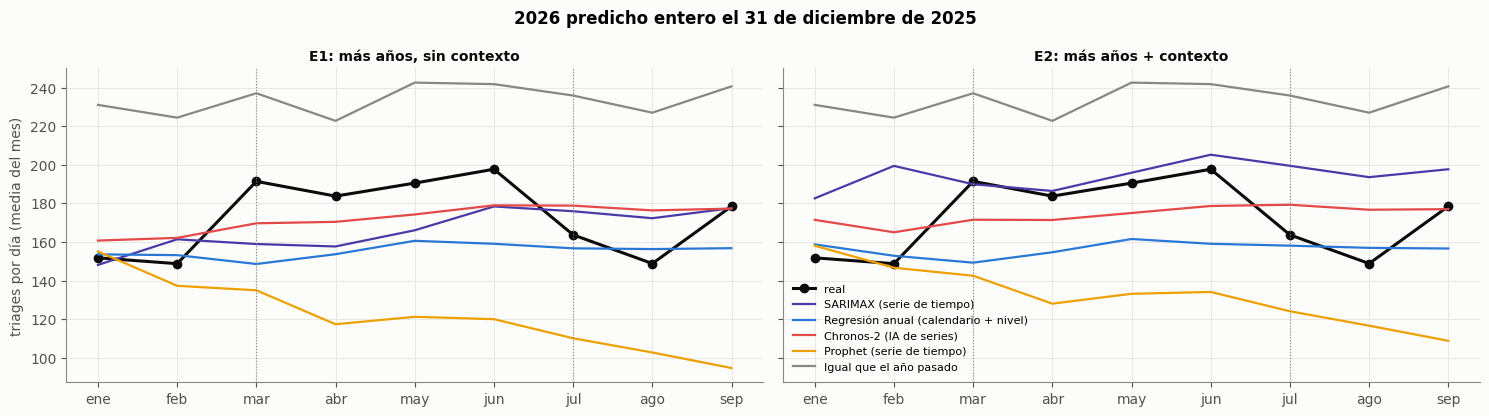

In [12]:
filas = []
for e in ["e1", "e2"]:
    PA, _ = pr.leer(exp=e, anio=True); PA = PA.dropna(subset=["real"])
    PA["mes"] = PA.fecha.dt.month; filas.append(PA.assign(exp=e))
A = pd.concat(filas)
M = A.groupby(["exp", "modelo", "mes"]).agg(pred=("q50", "mean"), lo=("q10", "mean"), hi=("q90", "mean"), real=("real", "mean")).reset_index()
M["error %"] = 100 * (M.pred - M.real) / M.real
display(M.pivot_table(index=["exp", "modelo"], columns="mes", values="error %").round(1))
resA = A.groupby(["exp", "modelo"]).apply(lambda g: pd.Series({
    "MAPE diario %": 100 * ((g.q50 - g.real).abs() / g.real).mean(),
    "error medio del mes %": 100 * (g.groupby("mes").q50.mean() / g.groupby("mes").real.mean() - 1).abs().mean(),
    "cob80 %": 100 * g.real.between(g.q10, g.q90).mean()}))
display(resA.round(1))

meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, e in zip(axes, ["e1", "e2"]):
    r = M[(M.exp == e)].groupby("mes").real.first()
    ax.plot(r.index, r.values, "o-", color=TINTA, lw=2.2, label="real")
    for m in ["sarimax", "regresion_anual", "chronos2_cal", "prophet", "anio_pasado"]:
        g = M[(M.exp == e) & (M.modelo == m)]
        if len(g): ax.plot(g.mes, g.pred, "-", color=color(m), lw=1.6, label=NOMBRE.get(m, m))
    ax.set_xticks(range(1, 10), meses); ax.set_title({"e1": "E1: más años, sin contexto", "e2": "E2: más años + contexto"}[e], fontsize=10)
axes[0].set_ylabel("triages por día (media del mes)"); axes[1].legend(fontsize=8)
for ax in axes:
    for f, t in [(3, "Nueva EPS"), (7, "Nueva EPS")]: ax.axvline(f, color=MUDO, ls=":", lw=.8)
fig.suptitle("2026 predicho entero el 31 de diciembre de 2025", fontweight="bold"); plt.tight_layout(); plt.show()

**Lectura.** Predecir 2026 entero el 31 de diciembre de 2025:

- **Chronos-2 (E1) es el mejor:** se equivoca un **8,9 %** en promedio en la media de cada mes, y su rango del 80 % contiene el 91 % de los días. Le sigue SARIMAX (E1), con 9,8 %.
- «Igual que el año pasado» falla un 37 %, porque 2025 era más alto.
- **El patrón del error es la red:** todos quedan por debajo de marzo a junio y por encima en julio-agosto. Coincide con los escalones de Nueva EPS, que nadie podía ver en diciembre.
- **A un año, el contexto no ayuda**, y a SARIMAX lo empeora (9,8 % → 14,0 %). El clima y la IRA de julio no se conocen en diciembre.

---
# 7. Prueba 3: la hora de saturación

La predicción del día del mejor modelo se reparte en horas con el **perfil horario por día de la
semana de 2025**, que se conoce el 31-12-2025. Se mide si acierta las horas de más carga.

Modelo: SARIMAX (serie de tiempo), a 1 día, 257 días de 2026
Hora pico acertada exacta: 23%; a ±1 hora: 62%
De las 3 horas de más carga, coinciden en promedio: 51%
Error por hora entre 8 y 20 h (MAPE): 33.5 %


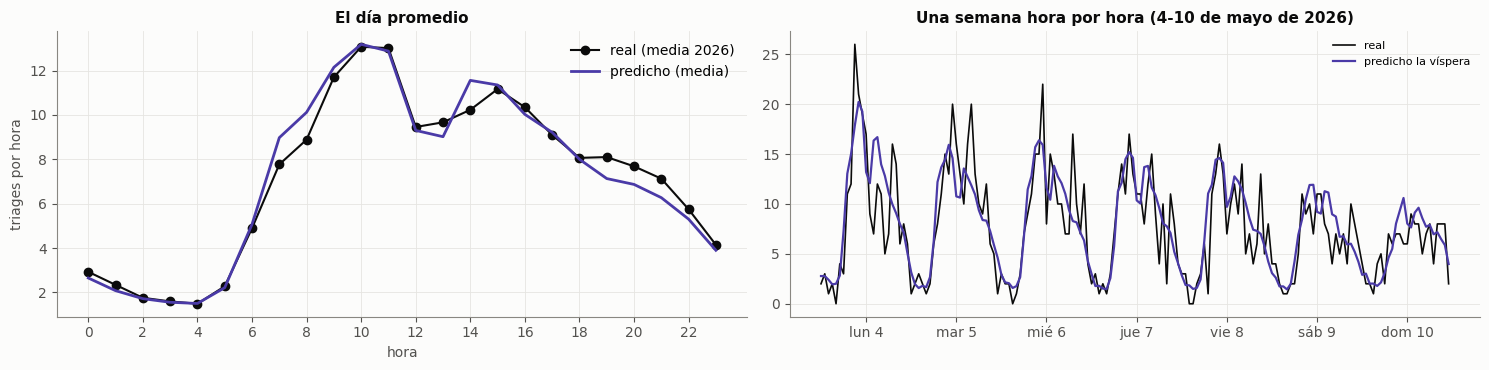

In [13]:
hor = pd.read_parquet(RAIZ / "salidas/triage_horario.parquet"); hor["dia"] = pd.to_datetime(hor.dia)
Hh = hor.pivot_table(index="dia", columns="hora", values="triages", aggfunc="sum").reindex(columns=range(24)).fillna(0)
ref = Hh.loc["2025-01-01":"2025-12-31"]
perfil = (ref.div(ref.sum(axis=1), axis=0)).groupby(ref.index.dayofweek).mean()
d1 = P2[(P2.modelo == mejor) & (P2.h == 1)].set_index("fecha")
real_h = Hh.reindex(d1.index)
pred_h = pd.DataFrame(d1.q50.values[:, None] * perfil.loc[d1.index.dayofweek].values, index=d1.index, columns=range(24))
dia_h = (pred_h - real_h).abs() / real_h.replace(0, np.nan)
pico_real, pico_pred = real_h.idxmax(axis=1), pred_h.idxmax(axis=1)
top3 = np.mean([len(set(real_h.loc[t].nlargest(3).index) & set(pred_h.loc[t].nlargest(3).index)) / 3 for t in d1.index])
print(f"Modelo: {NOMBRE.get(mejor, mejor)}, a 1 día, {len(d1)} días de 2026")
print(f"Hora pico acertada exacta: {(pico_real == pico_pred).mean():.0%}; a ±1 hora: {((pico_real - pico_pred).abs() <= 1).mean():.0%}")
print(f"De las 3 horas de más carga, coinciden en promedio: {top3:.0%}")
print(f"Error por hora entre 8 y 20 h (MAPE): {100 * dia_h.loc[:, 8:20].stack().mean():.1f} %")
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].plot(range(24), real_h.mean().values, "o-", color=TINTA, label="real (media 2026)")
axes[0].plot(range(24), pred_h.mean().values, "-", color=color(mejor), lw=2, label="predicho (media)")
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("hora"); axes[0].set_ylabel("triages por hora"); axes[0].legend(); axes[0].set_title("El día promedio")
sem = d1.index[(d1.index >= "2026-05-04") & (d1.index <= "2026-05-10")]
axes[1].plot(np.arange(len(sem) * 24), real_h.loc[sem].values.ravel(), color=TINTA, lw=1.2, label="real")
axes[1].plot(np.arange(len(sem) * 24), pred_h.loc[sem].values.ravel(), color=color(mejor), lw=1.6, label="predicho la víspera")
axes[1].set_xticks(np.arange(len(sem)) * 24 + 12, [f"{SEM[t.dayofweek]} {t.day}" for t in sem]); axes[1].legend(fontsize=8)
axes[1].set_title("Una semana hora por hora (4-10 de mayo de 2026)"); plt.tight_layout(); plt.show()

**Lectura.** Repartiendo el día predicho por SARIMAX con el perfil horario de 2025:

- **La hora pico se acierta con ±1 hora el 62 % de los días.** De las 3 horas de más carga, coinciden en promedio la mitad.
- **El error por hora es del 34 %.** Con 10-17 triages por hora, el azar puro ya da ±25-30 %.
- **Para operación, el mensaje útil es por franjas:** «mañana, saturación entre las 9 y las 11 h y entre las 14 y las 15 h».

---
# 8. Las razones: qué contexto pesa

Se ajustan dos modelos en el último origen (2026-09-13) con todo el contexto:
- **LightGBM** (mediana a 1 día): cuánto de su capacidad de separar días usa cada capa (ganancia);
- **la regresión**: cuánto mueve cada capa la predicción cuando sus variables se corren una desviación
  típica.

In [14]:
import lightgbm as lgb
pr.usar("e2")
o = pd.Timestamp(pr.ULTIMO_ORIGEN)
ctx = tuple(c.reindex(y.index) for c in pr.contexto(cal.index))
X = pr.rasgos(y, cal.reindex(y.index), 1, ctx).loc[:o]; yy = y.loc[:o]
ok = X.notna().all(axis=1) & yy.notna(); X, yy = X[ok], yy[ok]; X = X.loc[:, X.std() > 0]
m = lgb.LGBMRegressor(objective="quantile", alpha=.5, **pr.LightGBM.PARAM).fit(X, np.log(yy))
gan = pd.Series(m.booster_.feature_importance("gain"), index=X.columns)
capa = pd.Series(pr.capas(X.columns))
r = sm.NegativeBinomial(yy.values, sm.add_constant(X.values, has_constant="add")).fit(disp=0, maxiter=300)
b = pd.Series(r.params[1:-1], index=X.columns)
efecto = (b * X.std()).abs().groupby(capa).sum()
pesos = pd.DataFrame({"LightGBM: % de la ganancia": 100 * gan.groupby(capa).sum() / gan.sum(),
                      "Regresión: efecto de 1 desviación, % (suma de |efectos|)": 100 * (np.exp(efecto) - 1)}).sort_values("LightGBM: % de la ganancia", ascending=False)
display(pesos.round(1))
print("Las 12 variables externas más usadas por LightGBM (% de la ganancia):")
ext = gan[[c for c in gan.index if c.startswith(("ext_", "fut_"))]]
print((100 * ext / gan.sum()).sort_values(ascending=False).head(12).round(2).to_string())

C:\Users\ad6708\Documents\puebas\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(


,LightGBM: % de la ganancia,"Regresión: efecto de 1 desviación, % (suma de |efectos|)"
nivel,28.1,30.6
calendario,22.1,114.2
memoria,17.8,7.6
clima,9.0,3.2
salud,8.3,3.6
estacion,5.2,2.1
social,5.0,1.1
red,3.2,0.3
enso,0.8,0.9
eventos,0.5,10.4


Las 12 variables externas más usadas por LightGBM (% de la ganancia):
ext_red_nueva_peso                 1.70
ext_soc_lesiones_personales        1.59
ext_red_nueva_cambio               1.51
ext_sal_ira_total                  1.40
ext_sal_ev356                      1.28
ext_soc_homicidio                  1.21
ext_soc_violencia_intrafamiliar    1.14
ext_sal_ira_0_4                    1.11
ext_sal_consultas_todas            1.08
ext_soc_lesiones_transito          1.03
ext_cli_radiacion_cambio           0.97
ext_sal_ev300                      0.91


**Lectura.** Según LightGBM con todo el contexto:

- **Lo interno manda:** nivel 28 %, calendario 22 %, memoria 18 %.
- **Lo externo suma ~26 %**, sobre todo:
  - el peso de Nueva EPS;
  - lesiones personales;
  - IRA de Manizales;
  - clima.

El contexto **entra en las decisiones**, pero cada variable aporta poco, y en 2026 no se tradujo en mejores predicciones del total. La lectura que queda en pie:

- **El total lo mueven el calendario y la red**, como ya se había visto en los cuadernos 07, 13 y 14.
- **El efecto del entorno vive en subseries**, como la respiratoria del hospital (+10-14 %, cuaderno 13), y se diluye en el total.

---
# 9. MedGemma: ¿puede un modelo de lenguaje médico pronosticar?

A pedido del propietario: `medgemma:latest` (4,3 B) en el servidor de su superior, con 19 consultas, y
`medgemma1.5:4b` en local si se corrió. Reciben **la misma información que E2**, en texto: 8 semanas de
triage, el calendario y los eventos que vienen, y el contexto de la ciudad (IRA, clima, Nueva EPS,
lesiones). Dan un número por día, no una distribución, así que se comparan solo en el error del número
y en si aciertan la dirección (sube o baja), **en los mismos orígenes** que los demás.

In [15]:
PL, UL = pr.leer(exp="e2")
llm = PL[PL.modelo.str.startswith("llm")]
if len(llm):
    ors_llm = llm.origen.unique()
    comp = []
    for e in ["e0", "e1", "e2", "e3"]:
        P, _ = leer(e); comp.append(P[P.origen.isin(ors_llm)].assign(modelo=lambda d, e=e: d.modelo + " · " + e))
    comp.append(llm)
    CP, TL = pr.metricas(pd.concat(comp), UL)
    TL["dirección (sube/baja) %"] = CP.assign(ok=lambda d: (np.sign(d.d_pred) == np.sign(d.d_real))).groupby("modelo").ok.mean() * 100
    display(TL[["dirección (sube/baja) %", "error <=10 %", "MAPE %", "n"]].sort_values("MAPE %").round(1))
    print("Respuestas de MedGemma del servidor (los 7 números de cada consulta):")
    print(llm[llm.modelo.str.contains("servidor")].groupby("origen").q50.apply(lambda s: list(s.astype(int))).head(8).to_string())

,dirección (sube/baja) %,error <=10 %,MAPE %,n
modelo,,,,
sarimax · e0,69.9,63.2,8.8,133.0
sarimax · e1,65.4,66.9,8.8,133.0
sarimax · e3,61.7,61.7,8.9,133.0
lightgbm · e1,71.4,62.4,9.0,133.0
chronos2_cal · e3,72.9,63.2,9.0,133.0
glm_binneg · e1,66.2,62.4,9.0,133.0
glm_binneg · e3,63.2,63.9,9.1,133.0
chronos2_cal · e0,66.2,65.4,9.1,133.0
chronos2_cal · e1,67.7,63.2,9.1,133.0


Respuestas de MedGemma del servidor (los 7 números de cada consulta):
origen
2025-12-31      [145, 130, 120, 110, 100, 90, 80]
2026-01-14    [145, 138, 149, 134, 163, 193, 184]
2026-01-28    [158, 149, 165, 135, 170, 140, 152]
2026-02-11    [235, 240, 220, 210, 250, 230, 225]
2026-02-25    [158, 159, 160, 161, 162, 163, 164]
2026-03-11    [245, 220, 200, 190, 230, 210, 200]
2026-03-25    [235, 228, 210, 160, 190, 200, 215]
2026-04-08    [238, 215, 195, 200, 220, 210, 205]


**Lectura.** MedGemma (servidor, 4,3 B) es **el peor de todos**:

- error del 19,7 %;
- un tercio de los días con error de 10 % o menos.

Sus respuestas tienen escaleras que bajan de 10 en 10, números consecutivos y semanas sin la forma lunes-domingo. **Un modelo de lenguaje rellena números con forma de serie; no los pronostica.** Para series, la IA indicada es Chronos-2.

---
# 10. Depuración: qué se queda y qué sale

**Qué se queda y qué sale:**

| Modelo o técnica | Decisión | Por qué |
|---|---|---|
| **SARIMAX + LightGBM (combinación)** | **líder** | Mejor en casi todo, con el rango del 80 % exacto. Es la única que mejora a SARIMAX con significancia (meses estables) |
| **SARIMAX** (serie de tiempo que se corrige cada día) | se queda, como componente | Sigue los escalones de la red y da rangos honestos; empata en dirección |
| **LightGBM** (árboles con refuerzo, sin afinar) | se queda, como componente | Es la única señal en los meses estables, pero se confía de más solo |
| Jerárquico (Nueva EPS + resto) | se queda **para explicar** | Empata en precisión y separa cuánto de la predicción es Nueva EPS |
| Chronos-2 | se queda **para el año a ciegas** | Es el mejor a meses vista (8,9 % de error mensual) |
| Regresión | complemento | Da razones legibles; empata o pierde |
| XGBoost y GradientBoosting afinados | salen | No mejoran a LightGBM |
| Contexto externo sobre el total | **sale del modelo del total** | Empeora o no mejora en todas las familias |
| Prophet, MedGemma | salen | Peores que el control |

**Por técnica:** combinar una serie de tiempo con árboles de refuerzo es lo mejor. Le siguen cada uno por separado (empatados entre sí), después la IA preentrenada y la regresión, y al final las series sin memoria y los modelos de lenguaje.

---
# 11. Resumen de lo descubierto

## Resumen de lo descubierto (2026-10-05)

**El mejor modelo:** la **combinación SARIMAX + LightGBM**, que promedia una serie de tiempo que se corrige cada día y un ensamble de árboles de decisión con refuerzo. Usa los **registros de triage de 2020-2025 y el calendario de Colombia**. En 2026, que nunca vio:

- acierta si el día sube o baja frente a lo normal el **69 %** (vara de 28 días);
- **la cifra honesta de anticipar el día, con la vara rápida, es 64 %**;
- su rango del 80 % se cumple el **80,3 %**;
- error medio del **8,9 %**;
- media del mes con menos del 2 % de error;
- hora pico con ±1 hora el 62 % de los días.

**Lo que se aprendió:**

1. **La historia larga es lo que más mejora** a todos los modelos.
2. **El contexto externo no mejora la predicción del triage total**, ni con 8 ni con 49 variables. El efecto del entorno existe (cuaderno 13: +10-14 % en lo respiratorio), pero se diluye en el total.
3. **El nivel del total lo mueve Nueva EPS, a escalones imprevisibles.** Gran parte del «acierto» de 65-70 % era seguir esos escalones. Separar las dos varas fue clave para no engañarse.
4. **En los meses estables, solo los árboles anticipan algo** (58-63 %).
5. **Ningún modelo solo es claramente superior:** en dirección están empatados. Combinarlos sí mejora.

**Lo que falta:**

- **el calendario institucional de Nueva EPS** (pendiente #11). Es lo que más error explica;
- **probar el contexto en la serie respiratoria del hospital**, donde el efecto sí es grande;
- **la prueba prospectiva**: congelar la combinación y compararla con datos nuevos (re-extraer el triage).